# Welcome to the RandQuantKry Tutorial Part 2
 
This is the second part of the basic introduction to the usage of **RandQuantKry** on how to call the different evolution methods. <a href="tutorial.ipynb"><b>Part 1</b></a>, on how to set up a hamiltonian, an initial state and run a time evolution, along with the <a href="tutorial_benchmarking.ipynb"><b>benchmarking</b></a> and <a href="tutorial_parameter_study.ipynb"><b>parameter study</b></a> tutorials can be found in the respectively named Jupyter Notebooks. Have fun :)

In [76]:
# imports
import numpy as np
from randquantkry.benchmark import Benchmark
from randquantkry.evolution import (
    time_evolve_krylov,
    time_evolve_naive,
    time_evolve_randomized_krylov,
)

# these files can be found in src/ and are the main building blocks of this package
from randquantkry.hamiltonian import build_hamiltonian
from randquantkry.observables import plot_state_histogram, print_quantum_state

# utils/ contains all helper functions that allow for example logging
from randquantkry.utils.logging_config import configure_logging

In [77]:
configure_logging(console_level="INFO")

15:52:26 | INFO     | randquantkry | logging configured (console only)


<Logger randquantkry (DEBUG)>

Set up hamiltonian and initial state

In [78]:
n_qubits = 8
rng = np.random.default_rng(0)

terms = []
for i in range(n_qubits):
    terms.append(("X", i, float(rng.uniform(0.5, 1.5))))  # X field, every qubit
for i in range(n_qubits - 1):
    terms.append(("ZZ", i, float(rng.uniform(0.3, 0.8))))  # ZZ coupling, every neighboring pair

hamiltonian = build_hamiltonian(n_qubits, terms)

n_qubits = hamiltonian.num_qubits
initial_state = np.zeros(2**n_qubits, dtype=complex)
initial_state[128] = 1.0

15:52:26 | INFO     | randquantkry.hamiltonian | build_hamiltonian: built | {'context': {'n_qubits': 8, 'matrix_dim': 256, 'n_terms': 15}}


Previously we saw the naive time evolution approach, now we want to have a closer look at the classical Krylov approach.

The main idea is that instead of exponentiating the massive $2^n \times 2^n$ Hamiltonian $H$, the Krylov method projects the evolution onto a tiny $m$-dimensional subspace ($m \ll 2^n$) built by repeatedly applying $H$ to our initial state $|\psi_0\rangle$:

$$\mathcal{K}_m(H, |\psi_0\rangle) = \text{span} \{ |\psi_0\rangle, H|\psi_0\rangle, H^2|\psi_0\rangle, \dots, H^{m-1}|\psi_0\rangle \}$$

#### How It Works:
1. **Compress $H$:** Use Lanczos iteration to project $H$ down into a small $m \times m$ **tridiagonal matrix** $T_m$.
2. **Cheap Subspace Evolution:** Compute $e^{-i T_m t}$ on the tiny matrix (e.g., $20 \times 20$ instead of $256 \times 256$).
3. **Reconstruct State:** Map the result back to full Hilbert space: $|\psi(t)\rangle \approx V_m (e^{-i T_m t} e_1)$.

#### Parameter:

   * krylov_dim: The dimension of the Krylov subspace.

<div class="alert alert-block alert-info">
<b>Take away:</b>

For our 8-qubit system ($256 \times 256$), setting krylov_dim = 20 reduces our time-evolution problem from exponentiating a $256 \times 256$ matrix down to exponentiating a tiny $20 \times 20$ matrix!
</div>

In [79]:
evolved_state_krylov = time_evolve_krylov(hamiltonian, initial_state, time=1.0, krylov_dim=20)

15:52:26 | INFO     | randquantkry.evolution | time_evolve_krylov: starting | {'context': {'n_qubits': 8, 'matrix_dim': 256, 'time': 1.0, 'krylov_dim_requested': 20}}
15:52:26 | INFO     | randquantkry.evolution | time_evolve_krylov: basis built | {'context': {'krylov_dim_requested': 20, 'k_reached': 20, 'Tri_shape': (20, 20)}}
15:52:26 | INFO     | randquantkry.evolution | time_evolve_krylov: complete | {'context': {'evolved_state_norm': 1.0}}


In [80]:
print_quantum_state(evolved_state_krylov)

|ψ⟩ = (+0.0593-0.0897j) |00000000⟩ + (+0.0321-0.1044j) |00000001⟩ + (+0.0290-0.0352j) |00000010⟩ + (-0.1555-0.0911j) |00000011⟩ + (+0.0145-0.0505j) |00000100⟩ + (+0.0008-0.0357j) |00000101⟩ + (+0.0174-0.0304j) |00000110⟩ + (-0.1224-0.0077j) |00000111⟩ + (+0.0079-0.0402j) |00001000⟩ + (-0.0192-0.0693j) |00001001⟩ + (-0.0132+0.0024j) |00001010⟩ + (-0.0122-0.0165j) |00001011⟩ + (-0.0960-0.1666j) |00001100⟩ + (-0.0928-0.1561j) |00001101⟩ + (-0.0831-0.0974j) |00001110⟩ + (-0.2190+0.3233j) |00001111⟩ + (+0.0026-0.0425j) |00010000⟩ + (-0.0075-0.0407j) |00010001⟩ + (+0.0037-0.0200j) |00010010⟩ + (-0.0755+0.0020j) |00010011⟩ + (+0.0022-0.0088j) |00010100⟩ + (+0.0002-0.0012j) |00010101⟩ + (+0.0065-0.0076j) |00010110⟩ + (-0.0302-0.0019j) |00010111⟩ + (-0.0094-0.0212j) |00011000⟩ + (-0.0304-0.0194j) |00011001⟩ + (-0.0004+0.0030j) |00011010⟩ + (-0.0224-0.0063j) |00011011⟩ + (-0.0925-0.0112j) |00011100⟩ + (-0.0880-0.0080j) |00011101⟩ + (-0.0606+0.0038j) |00011110⟩ + (+0.0595+0.1774j) |00011111⟩ + (+

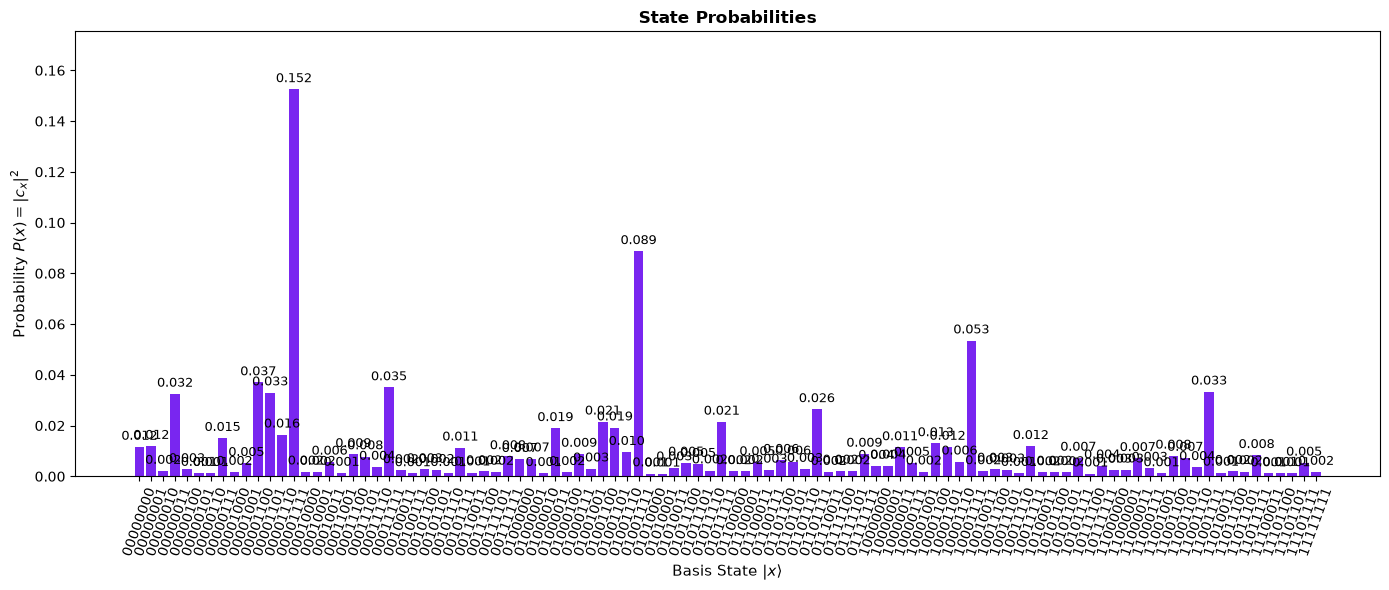

In [81]:
plot_state_histogram(evolved_state_krylov)

That definitely looks like something happened lets check back with our naive approach: 

15:52:27 | INFO     | randquantkry.evolution | time_evolve_naive: starting | {'context': {'n_qubits': 8, 'matrix_dim': 256, 'time': 1.0}}
15:52:28 | INFO     | randquantkry.evolution | time_evolve_naive: complete | {'context': {'evolved_state_norm': 1.0}}


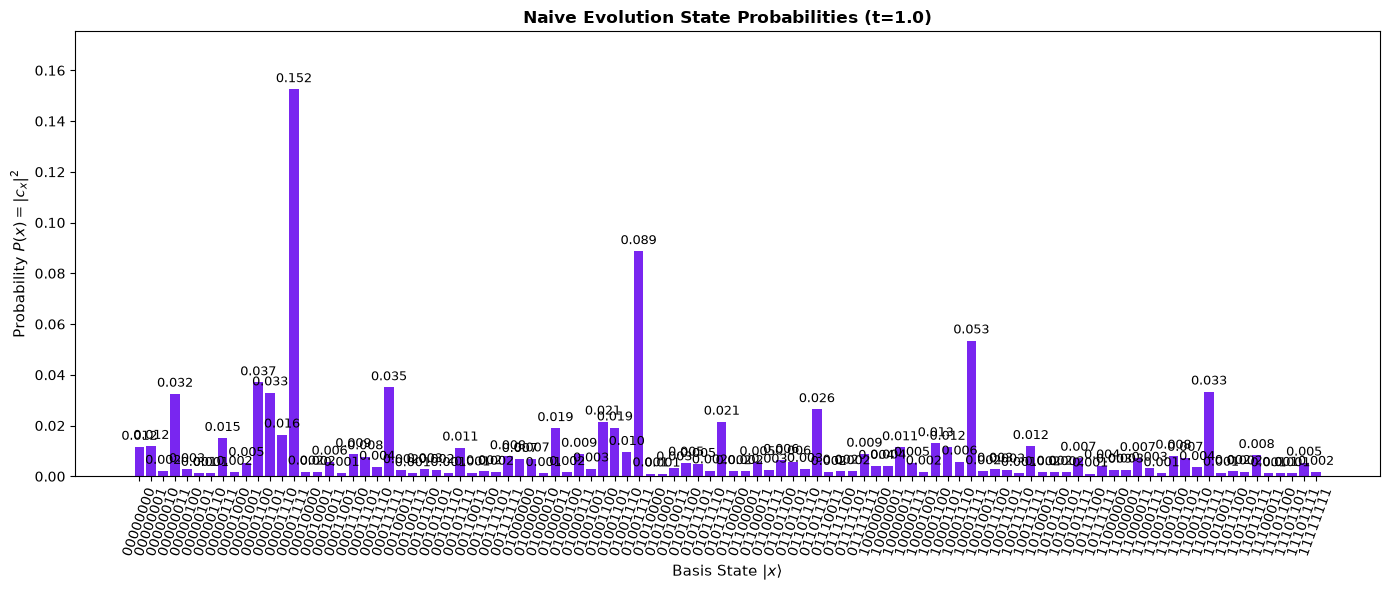

In [82]:
_, evolved_state_naive = time_evolve_naive(hamiltonian, initial_state, time=1.0)

plot_state_histogram(evolved_state_naive, title="Naive Evolution State Probabilities (t=1.0)")

That looks good from a qualitative stand point let's actually confirm this by calculating the relative error:

In [83]:
rel_error = Benchmark.calculate_rel_error(evolved_state_krylov, evolved_state_naive)
print(f"Relative Error: {rel_error}")

Relative Error: 2.0247252710451806e-07


If we want to make that error better we can simply increase the Krylov dimensions:

In [84]:
evolved_state_krylov_40 = time_evolve_krylov(hamiltonian, initial_state, time=1.0, krylov_dim=40)

15:52:29 | INFO     | randquantkry.evolution | time_evolve_krylov: starting | {'context': {'n_qubits': 8, 'matrix_dim': 256, 'time': 1.0, 'krylov_dim_requested': 40}}
15:52:29 | INFO     | randquantkry.evolution | time_evolve_krylov: basis built | {'context': {'krylov_dim_requested': 40, 'k_reached': 40, 'Tri_shape': (40, 40)}}
15:52:29 | INFO     | randquantkry.evolution | time_evolve_krylov: complete | {'context': {'evolved_state_norm': 1.0}}


In [85]:
rel_error_40 = Benchmark.calculate_rel_error(evolved_state_krylov_40, evolved_state_naive)
print(f"Relative Error: {rel_error_40}")

Relative Error: 3.4420999360210717e-15


<div class="alert alert-block alert-info">
<b>Continued in ...</b> 

This motivates a parameter study, which is introduced in  <a href="turtorial_parameter_study.ipynb"><b>tutorial_paramter_study.ipynb</b></a>.
</div>

Randomized krylov is the second approach implemented to see if this would push the computational bounds even further. 

While classical Lanczos reduces memory by projecting $H$ onto a small subspace, orthogonalizing full $N = 2^n$ dimensional state vectors still incurs significant $\mathcal{O}(N)$ memory and compute costs at each iteration. **Randomized Krylov** uses *randomized sketching* (via Subsampled Randomized Hadamard/Cosine Transforms) to compress high-dimensional vectors down to a drastically smaller sketch space.

#### How It Works:
1. **Sketch Matrix $S$:** Construct an $s \times N$ random projection using Discrete Cosine Transforms (DCT) + random sign flips.
2. **Sketched Orthogonalization:** Compute overlaps and project vectors using the lightweight $s$-dimensional representations ($S v$) instead of full $N$-dimensional vectors.
3. **Solve & Lift:** Form the reduced operator $\tilde{H}$ in sketch space, compute $e^{-i \tilde{H} t}$, and lift the final solution back to the physical state space.

#### Parameters

 * num_random_vectors : The number of random vectors to use in the randomized Krylov method as an *int*, for best solution with krylov dimension k set to ($2k + 1$)

 * trunc : The truncation parameter for the randomized Krylov method also *int*, as a default it is set to 2.

 * seed : Random seed, set to 67 :)

In [86]:
evolved_state_randkry = time_evolve_randomized_krylov(
    hamiltonian, initial_state, time=1.0, krylov_dim=20, num_random_vectors=41, trunc=2, seed=67
)

15:52:29 | INFO     | randquantkry.evolution | time_evolve_randomized_krylov: starting | {'context': {'n_qubits': 8, 'matrix_dim': 256, 'time': 1.0, 'krylov_dim_requested': 20, 'num_random_vectors': 41}}
15:52:29 | INFO     | randquantkry.evolution | time_evolve_randomized_krylov: complete | {'context': {'evolved_state_norm': 0.9999999870566216}}


In [87]:
print_quantum_state(evolved_state_randkry)

|ψ⟩ = (+0.0593-0.0897j) |00000000⟩ + (+0.0321-0.1044j) |00000001⟩ + (+0.0290-0.0352j) |00000010⟩ + (-0.1555-0.0911j) |00000011⟩ + (+0.0145-0.0505j) |00000100⟩ + (+0.0008-0.0357j) |00000101⟩ + (+0.0174-0.0304j) |00000110⟩ + (-0.1224-0.0077j) |00000111⟩ + (+0.0079-0.0402j) |00001000⟩ + (-0.0192-0.0693j) |00001001⟩ + (-0.0132+0.0024j) |00001010⟩ + (-0.0122-0.0165j) |00001011⟩ + (-0.0960-0.1666j) |00001100⟩ + (-0.0928-0.1561j) |00001101⟩ + (-0.0831-0.0974j) |00001110⟩ + (-0.2190+0.3233j) |00001111⟩ + (+0.0026-0.0425j) |00010000⟩ + (-0.0075-0.0407j) |00010001⟩ + (+0.0037-0.0200j) |00010010⟩ + (-0.0755+0.0020j) |00010011⟩ + (+0.0022-0.0088j) |00010100⟩ + (+0.0002-0.0012j) |00010101⟩ + (+0.0065-0.0076j) |00010110⟩ + (-0.0302-0.0019j) |00010111⟩ + (-0.0094-0.0212j) |00011000⟩ + (-0.0304-0.0194j) |00011001⟩ + (-0.0004+0.0030j) |00011010⟩ + (-0.0224-0.0063j) |00011011⟩ + (-0.0925-0.0112j) |00011100⟩ + (-0.0880-0.0080j) |00011101⟩ + (-0.0606+0.0038j) |00011110⟩ + (+0.0595+0.1774j) |00011111⟩ + (+

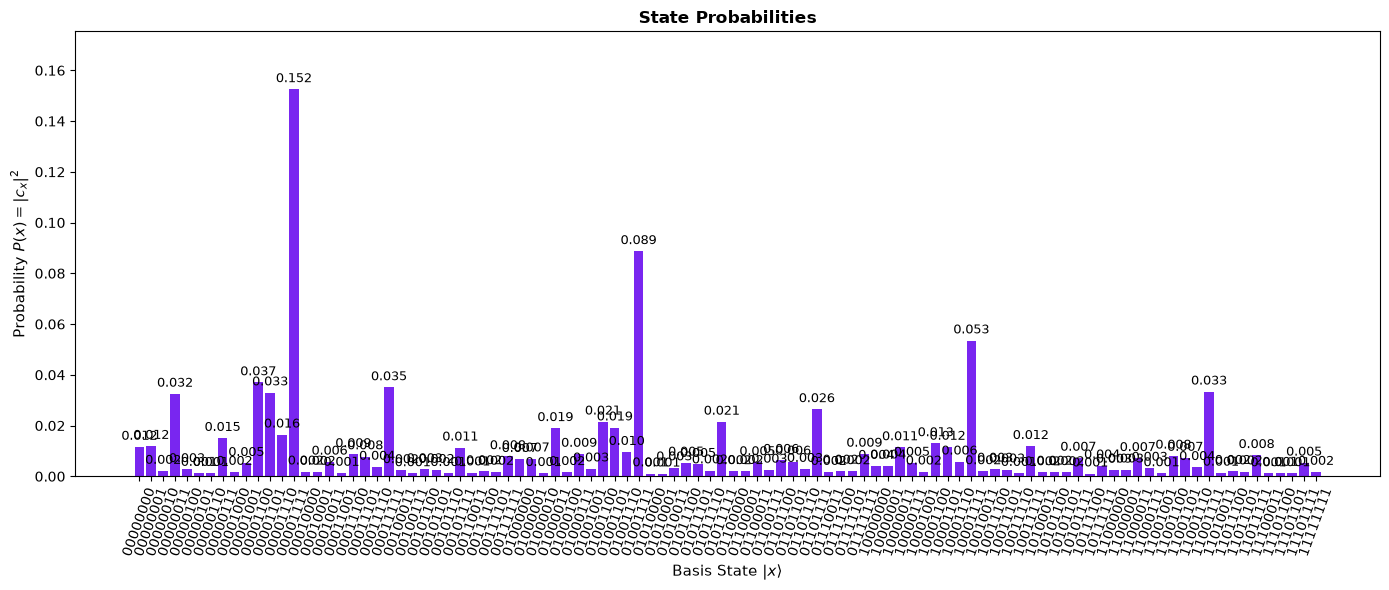

In [88]:
plot_state_histogram(evolved_state_randkry)

In [89]:
rel_error_randkry = Benchmark.calculate_rel_error(evolved_state_randkry, evolved_state_naive)
print(f"Relative error: {rel_error_randkry}")

Relative error: 2.926195775192679e-07


In [90]:
evolved_state_randkry = time_evolve_randomized_krylov(
    hamiltonian, initial_state, time=1.0, krylov_dim=40, num_random_vectors=81, trunc=2, seed=67
)

15:52:30 | INFO     | randquantkry.evolution | time_evolve_randomized_krylov: starting | {'context': {'n_qubits': 8, 'matrix_dim': 256, 'time': 1.0, 'krylov_dim_requested': 40, 'num_random_vectors': 81}}
15:52:30 | INFO     | randquantkry.evolution | time_evolve_randomized_krylov: complete | {'context': {'evolved_state_norm': 1.0000000000000009}}


In [91]:
rel_error_randkry = Benchmark.calculate_rel_error(evolved_state_randkry, evolved_state_naive)
print(f"Relative error: {rel_error_randkry}")

Relative error: 4.488808200348558e-15


That is also a very good error ! By now you are hopefully wondering which performs better Krylov or randomized Krylov and that is exactly what the  <a href="tutorial_benchmarking.ipynb"><b>benchmarking tutorial</b></a> explores.

<div class="alert alert-block alert-info">
<b>Bonus: </b> 

There are two more randomized Krylov methods implemented in <a href="../src/evolution.py"><b>src/evolution.py</b></a>:
* **time_evolve_randomized_krylov_gaussian**
* **time_evolve_randomized_krylov_gramschmidt** 

They take the same arguments as time_evolve_randomized_krylov in case you want to try them out. :)
</div>